# FACECAST

In this notebook we are going to build a network that takes a 16×16 picture of a face and produces a 128×128 picture of it. That is 8× upscaling per side, so the output has 64 times more pixels than the input. Most of the output cannot be *recovered* from the input, it has to be *invented* in a plausible way, which is why the task is called **face hallucination**. We are going to use the CelebA dataset and you can learn more about it [here](https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html). For now, this notebook consists of the following steps:
* Environment setup
* Dataset download
* Data preprocessing
* Degradation (making the low-resolution inputs)

The rest (baselines, the network, training and evaluation) will be added step by step.

### Step 0: Environment Setup

The dependencies are listed in `pyproject.toml` and managed by [uv](https://docs.astral.sh/uv/). Run `uv sync` once in the project folder, it creates the `.venv` environment with everything installed. Then select `.venv` as the kernel of this notebook.

Note that `pip` is not available in a uv environment, so `%pip install` does not work here. To add a new package, use `uv add <package>` in the terminal.

In [1]:
import os
# Folder for the downloads (has to be set before datasets is imported)
data_dir = os.path.abspath('data')
os.environ['HF_HOME'] = data_dir

import random
import cv2
import numpy as np
import torch
import torch.nn.functional as F
import torchvision
import datasets
from datasets import load_dataset
from PIL import Image
from tqdm.auto import tqdm

from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [15, 10]

# Set the seed for reproducibility (python, numpy and torch)
random.seed(1234)
np.random.seed(1234)
torch.manual_seed(1234)

# Use the GPU if there is one
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('PyTorch:     ', torch.__version__)
print('Torchvision: ', torchvision.__version__)
print('Datasets:    ', datasets.__version__)
print('Data folder: ', data_dir)
print('Device:      ', device, '-', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'no GPU found')

PyTorch:      2.11.0+cu128
Torchvision:  0.26.0+cu128
Datasets:     5.2.0
Data folder:  /home/anton/PycharmProjects/facecast/data
Device:       cuda - NVIDIA GeForce RTX 5090


### Step 1: Dataset Download

Download the CelebA dataset (aligned and cropped faces) from Hugging Face. Everything we download goes to the `data` folder (we pointed `HF_HOME` to it in the previous step), which is not tracked by git.

The download is about 11.7 GB and the prepared copy takes the same again, so you need about 24 GB of free space and the first run takes a while. The next runs find the files in `data` and load them right away.

In [2]:
# Download the dataset (or load it from the data folder if it is already there)
dataset = load_dataset('flwrlabs/celeba')

# The dataset comes with the official train / validation / test split
train_set, val_set, test_set = dataset['train'], dataset['valid'], dataset['test']

print('Train set:      ', len(train_set), 'samples')
print('Validation set: ', len(val_set), 'samples')
print('Test set:       ', len(test_set), 'samples')

Train set:       162770 samples
Validation set:  19867 samples
Test set:        19962 samples


Make a quick inspection to check that the download is fine.

Columns:     42 - ['image', 'celeb_id', '5_o_Clock_Shadow', 'Arched_Eyebrows'] ...
Image size:  (178, 218) RGB


Identities:  8192 in the train set


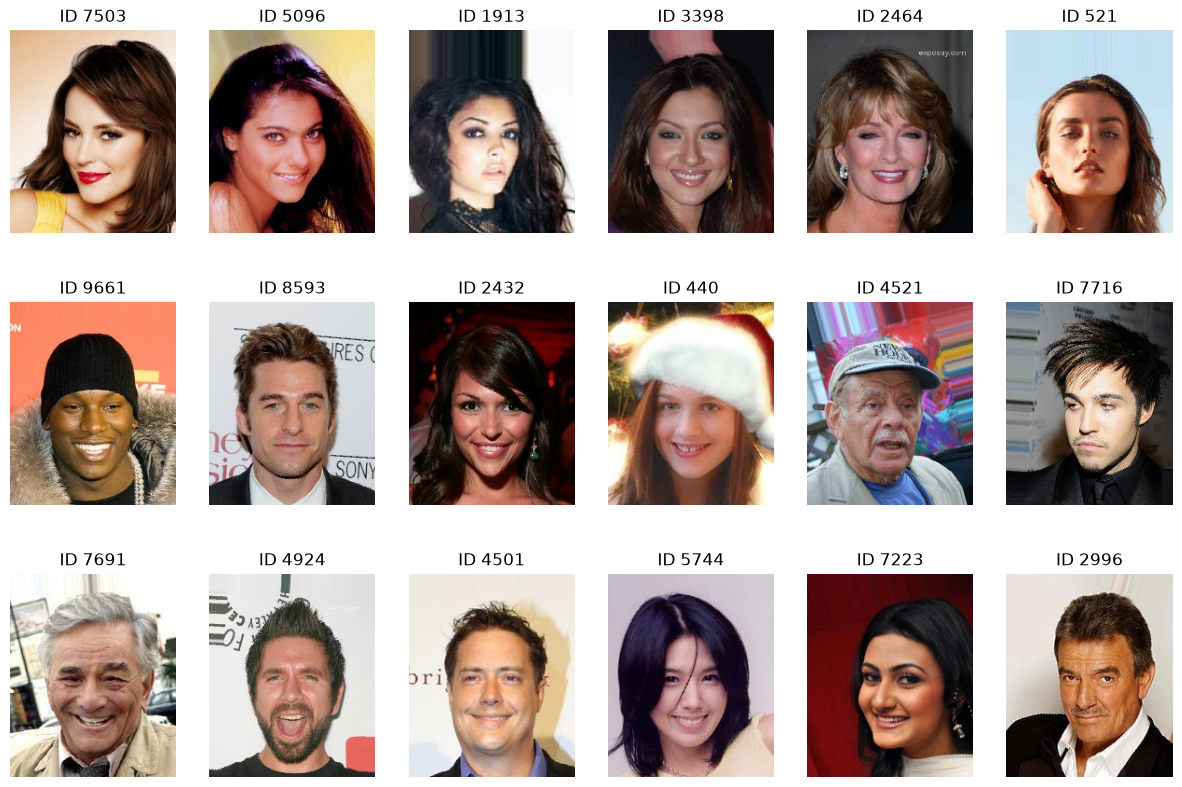

In [3]:
# Every sample is an image, the ID of the person and 40 binary attributes
sample = train_set[0]
print('Columns:    ', len(train_set.column_names), '-', train_set.column_names[:4], '...')
print('Image size: ', sample['image'].size, sample['image'].mode)
print('Identities: ', len(set(train_set['celeb_id'])), 'in the train set')

# Visualize random samples (as a plot with 3x6 samples)
for ii in range(18):
    plt.subplot(3,6,ii+1)
    # Pick a random sample
    idx = np.random.randint(0, len(train_set))
    # Show the image and the ID of the person
    plt.imshow(train_set[idx]['image'])
    plt.title('ID ' + str(train_set[idx]['celeb_id']))
    plt.axis('off')

### Step 2: Data Preprocessing

The CelebA images are 178×218, but we want square 128×128 faces as the high-resolution (HR) targets. So every image is center-cropped to a square (178×178) and resized to 128×128.

Decoding 160k images takes a few minutes, and we do not want to repeat it in every epoch. Therefore, the preprocessed faces are stored once in the `data` folder as plain `uint8` arrays (about 8 GB for the train set). The next runs just open these files. They are opened as memory maps, so only the faces we actually ask for are read from the disk.

We use the whole train set, and the first 2000 faces of the validation and the test set.

In [4]:
# Dataset params
hr_size = 128     # size of the high-resolution face
num_val = 2000    # faces used for the validation during training
num_test = 2000   # faces used for the final evaluation

def preprocess(img):
    # Center-crop the image to a square
    img = img.convert('RGB')
    w, h = img.size
    s = min(w, h)
    left, top = (w - s)//2, (h - s)//2
    img = img.crop((left, top, left + s, top + s))
    # Resize it to the HR size
    img = img.resize((hr_size, hr_size), Image.LANCZOS)
    return np.asarray(img, dtype=np.uint8)

def load_split(split, name):
    path = os.path.join(data_dir, 'celeba_%s_%d_%d.npy' % (name, hr_size, len(split)))
    if not os.path.exists(path):
        # Preprocess the images one by one and write them straight to the disk
        tmp = path + '.tmp'
        arr = np.lib.format.open_memmap(tmp, mode='w+', dtype=np.uint8, shape=(len(split), hr_size, hr_size, 3))
        for ii, sample in enumerate(tqdm(split, desc='Preprocessing ' + name)):
            arr[ii] = preprocess(sample['image'])
        arr.flush()
        del arr
        # Rename the file at the very end, so an interrupted run never leaves a half-written file
        os.replace(tmp, path)
    # Open the file as a read-only memory map
    return np.load(path, mmap_mode='r')

# Preprocess the splits (or open them from the data folder if they are already there)
hr_train = load_split(train_set.select_columns(['image']), 'train')
hr_val = load_split(val_set.select_columns(['image']).select(range(num_val)), 'val')
hr_test = load_split(test_set.select_columns(['image']).select(range(num_test)), 'test')

print('Train set:      ', hr_train.shape, hr_train.dtype)
print('Validation set: ', hr_val.shape)
print('Test set:       ', hr_test.shape)
print('Range:          ', hr_test.min(), '-', hr_test.max())

Train set:       (162770, 128, 128, 3) uint8
Validation set:  (2000, 128, 128, 3)
Test set:        (2000, 128, 128, 3)
Range:           0 - 255


Compare a few original images (top row) with their preprocessed versions (bottom row).

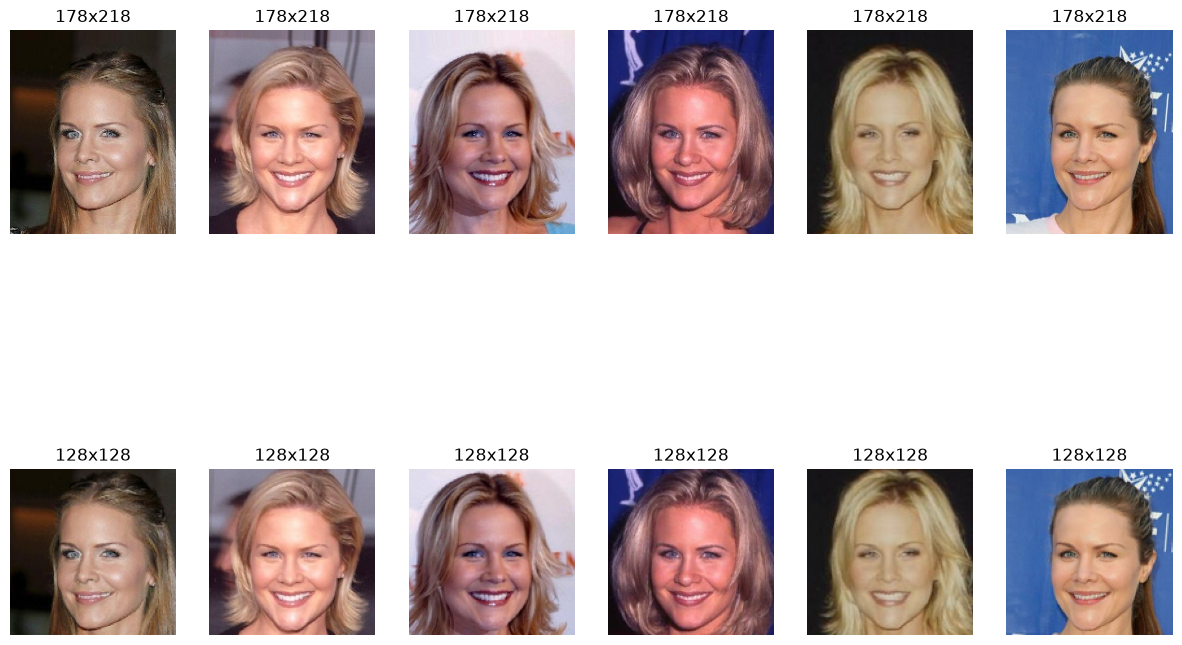

In [5]:
# Show the first test samples before and after the preprocessing
for ii in range(6):
    img = test_set[ii]['image']
    plt.subplot(2,6,ii+1), plt.imshow(img)
    plt.title('%dx%d' % img.size), plt.axis('off')
    plt.subplot(2,6,ii+7), plt.imshow(hr_test[ii])
    plt.title('%dx%d' % hr_test[ii].shape[:2]), plt.axis('off')

### Step 3: Degradation

The network needs pairs of low-resolution (LR) inputs and HR targets. We only have the HR faces, so we make the LR inputs ourselves: every 8×8 block of pixels is averaged to a single pixel, which turns a 128×128 face into a 16×16 one. The result is rounded to 8 bits, because that is what a real image file would contain.

The LR images are not stored. It is cheaper to compute them on the GPU from every HR batch.

We also need two small helpers to move the data between the `uint8` arrays of shape (N, H, W, 3) and the float tensors of shape (N, 3, H, W) in the 0 - 1 range that PyTorch works with.

In [6]:
scale = 8                    # upscaling factor
lr_size = hr_size // scale   # size of the low-resolution face

def to_tensor(u8):
    # (N,H,W,3) uint8 array -> (N,3,H,W) float tensor in 0 - 1 on the device
    return torch.from_numpy(np.array(u8)).to(device).permute(0, 3, 1, 2).float()/255

def to_u8(t):
    # (N,3,H,W) float tensor -> (N,H,W,3) uint8 array
    return (t.float().clamp(0, 1)*255).round().byte().permute(0, 2, 3, 1).cpu().numpy()

def degrade(hr):
    # Average every scale x scale block of pixels
    lr = F.avg_pool2d(hr, scale)
    # Round to 8 bits
    return torch.round(lr*255)/255

hr = to_tensor(hr_test[:6])
lr = degrade(hr)

print('HR batch: ', tuple(hr.shape))
print('LR batch: ', tuple(lr.shape))
print('Pixels:   ', hr_size*hr_size, '->', lr_size*lr_size, '(%dx fewer)' % (scale*scale))

HR batch:  (6, 3, 128, 128)
LR batch:  (6, 3, 16, 16)
Pixels:    16384 -> 256 (64x fewer)


For an integer factor, the block averaging is the same thing as `cv2.resize` with the `INTER_AREA` interpolation. Let's check it, the two results may differ by 1 gray level at most (because of the rounding).

In [7]:
# Degrade the same faces with OpenCV
lr_gpu = to_u8(lr)
lr_cv2 = np.stack([cv2.resize(img, (lr_size, lr_size), interpolation=cv2.INTER_AREA) for img in hr_test[:6]])

diff = np.abs(lr_gpu.astype(int) - lr_cv2.astype(int))
print('Max difference: ', diff.max(), 'gray levels')
print('Pixels equal:   ', '%.1f %%' % (100*np.mean(diff == 0)))

Max difference:  1 gray levels
Pixels equal:    99.3 %


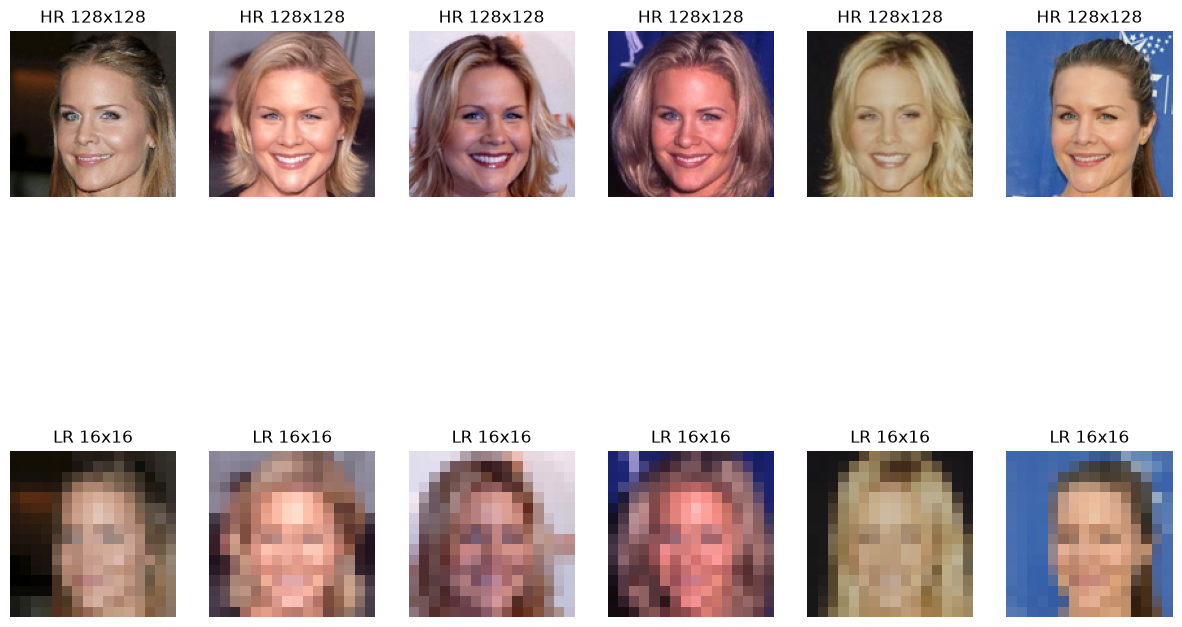

In [8]:
# Show the HR targets (top row) and the LR inputs (bottom row)
for ii in range(6):
    plt.subplot(2,6,ii+1), plt.imshow(hr_test[ii])
    plt.title('HR %dx%d' % (hr_size, hr_size)), plt.axis('off')
    # Show the LR pixels as they are, without smoothing
    plt.subplot(2,6,ii+7), plt.imshow(lr_gpu[ii], interpolation='nearest')
    plt.title('LR %dx%d' % (lr_size, lr_size)), plt.axis('off')